# Diabetic Retinopathy using VGG16 & VGG19   

## 1. Import Library

In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
import pickle
import numpy as np
import matplotlib.pyplot as plt
# 1. IMPORT TẤT CẢ KIẾN TRÚC EFFICIENTNET TỪ B0 ĐẾN B4
from tensorflow.keras.applications import (
    EfficientNetB0, 
    EfficientNetB1, 
    EfficientNetB2, 
    EfficientNetB3, 
    EfficientNetB4
)
# Hàm tiền xử lý dùng chung cho toàn bộ họ EfficientNet
from tensorflow.keras.applications.efficientnet import preprocess_input as preprocess_effnet

I0000 00:00:1784826719.032914   39136 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1784826722.529942   39136 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1784826793.677436   39136 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [ ]:
MODEL_VERSION = ["B0", "B1", "B2", "B3", "B4"]
EFFNET_DICT = {
    "B0": EfficientNetB0,
    "B1": EfficientNetB1,
    "B2": EfficientNetB2,
    "B3": EfficientNetB3,
    "B4": EfficientNetB4
}

In [2]:
# Xóa rác bộ nhớ GPU
tf.keras.backend.clear_session()

## 2. Load Data

In [3]:
BATCH_SIZE=4

In [ ]:
with open("../../../data/processed/aptos/sample_100/sample_dataset.pkl", "rb") as f: #[cite: 1]
    data = pickle.load(f)

In [5]:
with open("../../../data/processed/aptos/test_images/sample_dataset.pkl", "rb") as f:
    data_test = pickle.load(f)

## 3. Data Preprocessing 

In [6]:
X = data['data']
y = data['labels']
class_names = data['class_names']
NUM_CLASSES = len(class_names)
x_train, x_val, y_train, y_val = train_test_split(
    X,y, test_size=0.2, random_state=42, stratify=y
)
IMG_SIZE = x_train.shape[1]
print(f'Số mẫu: {len(y_train)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 200 | Số lớp: 5 | Kích thước ảnh: 300x300


In [7]:
x_test = data_test['data']
y_test = data_test['labels']
print(f'Số mẫu: {len(y_test)} | Số lớp: {NUM_CLASSES} | Kích thước ảnh: {IMG_SIZE}x{IMG_SIZE}')

Số mẫu: 366 | Số lớp: 5 | Kích thước ảnh: 300x300


In [8]:
y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test  = tf.keras.utils.to_categorical(y_test,  NUM_CLASSES)
y_val = tf.keras.utils.to_categorical(y_val, NUM_CLASSES)

In [ ]:
def preprocess_function_effnet(image, label): 
    image = tf.cast(image, tf.float32)
    image = preprocess_effnet(image)
    return image, label

### Xử lí data trước khi train 

In [ ]:
# 3. KHỞI TẠO TẬP DATASET TRAIN
with tf.device('/CPU:0'):
    train_dataset = tf.data.Dataset.from_tensor_slices((x_train, y_train))
    # Áp dụng hàm tiền xử lý (map) và cho phép CPU tự động tối ưu luồng (AUTOTUNE)
    train_dataset = train_dataset.map(preprocess_function_effnet, num_parallel_calls=tf.data.AUTOTUNE)
    # Chia lô (batch) và nạp sẵn dữ liệu cho vòng lặp kế tiếp (prefetch) để tăng tốc GPU
    train_dataset = train_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    test_dataset = tf.data.Dataset.from_tensor_slices((x_test, y_test))
    test_dataset = test_dataset.map(preprocess_function_effnet, num_parallel_calls=tf.data.AUTOTUNE)
    test_dataset = test_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    val_dataset = tf.data.Dataset.from_tensor_slices((x_val, y_val))
    val_dataset = val_dataset.map(preprocess_function_effnet, num_parallel_calls=tf.data.AUTOTUNE)
    val_dataset = val_dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

I0000 00:00:1784826861.984925   39136 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


### Ảnh tệp train

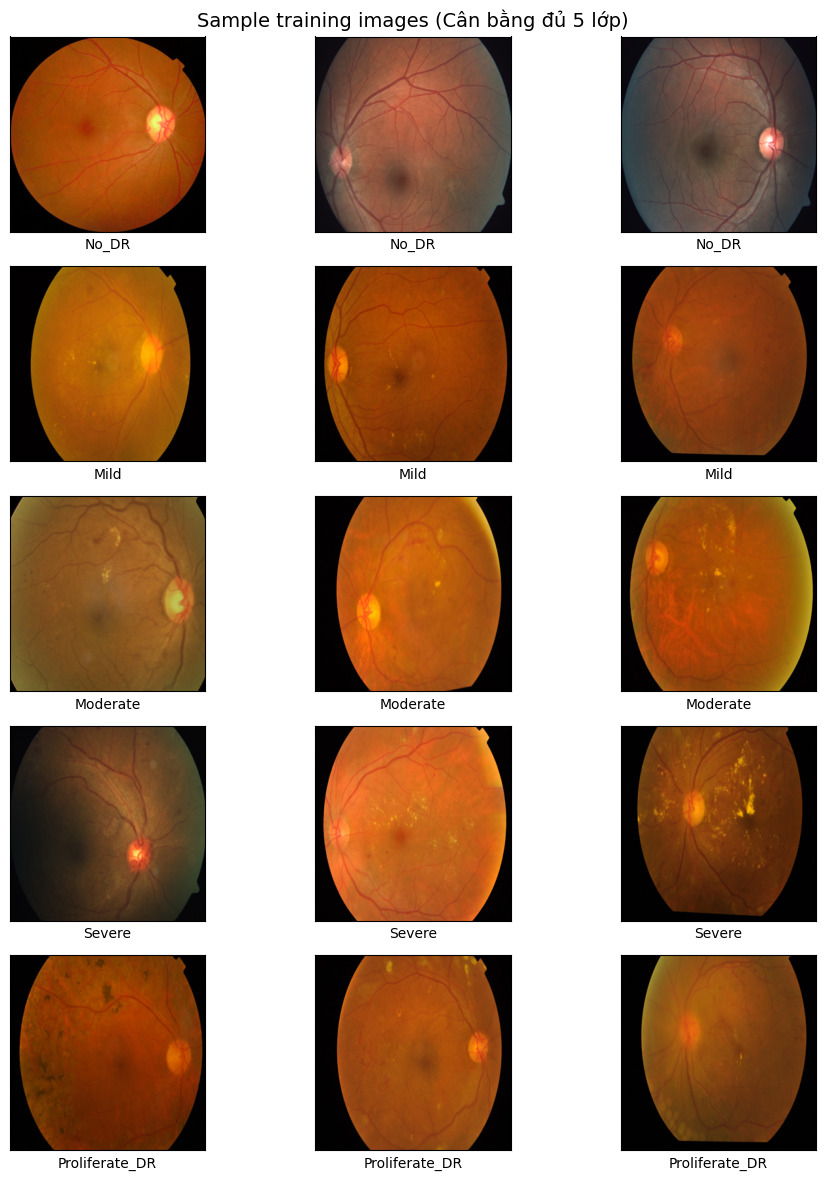

In [12]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_train, axis=1) if len(y_train.shape) > 1 else y_train

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_train[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample training images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

### Ảnh tệp test

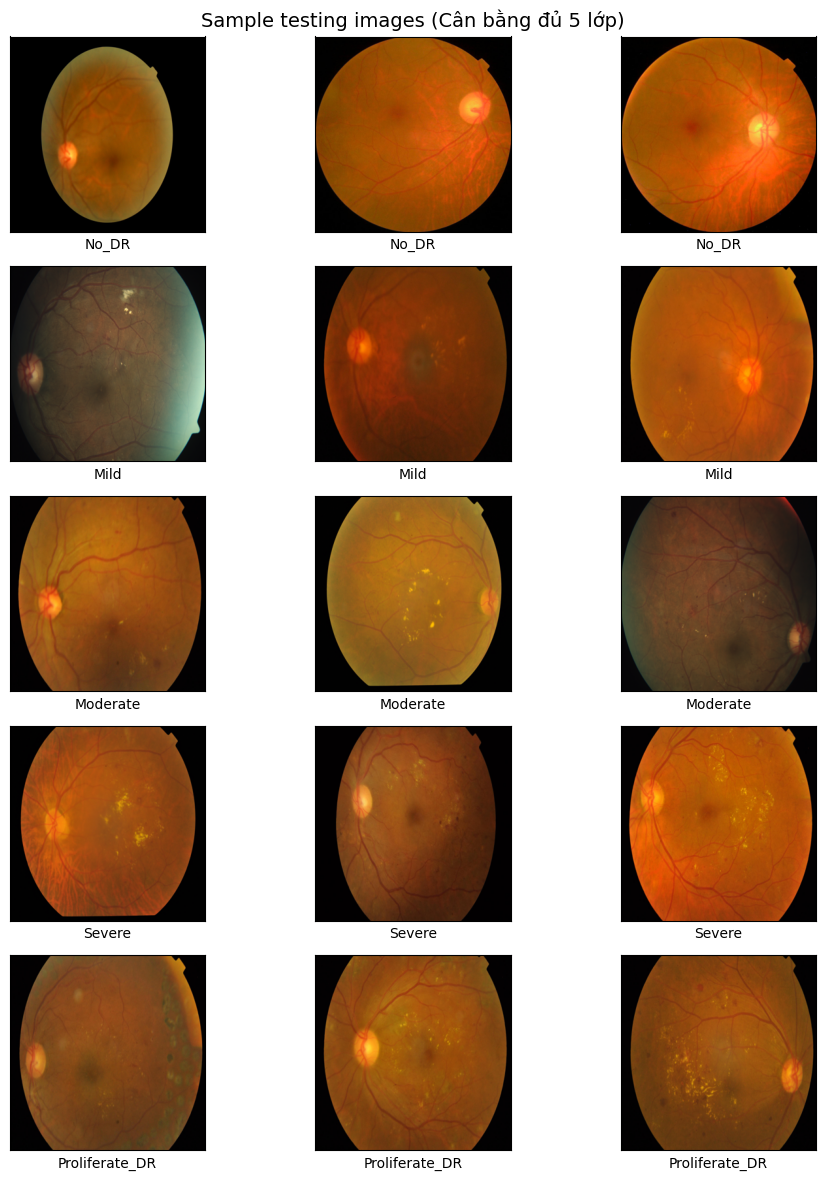

In [13]:
# 1. Chuyển y_train về dạng nhãn số 1D (nếu đang là One-hot encoding)
y_labels = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test

num_classes = len(class_names)  # 5 lớp
samples_per_class = 3           # Số ảnh ngẫu nhiên lấy từ mỗi lớp (5 lớp x 3 = 15 ảnh)

plt.figure(figsize=(10, 12))

plot_idx = 1
for class_id in range(num_classes):
    # Lấy toàn bộ vị trí (index) của ảnh thuộc lớp class_id
    indices = np.where(y_labels == class_id)[0]
    
    # Chọn ngẫu nhiên N ảnh từ các vị trí đó
    selected_indices = np.random.choice(indices, samples_per_class, replace=False)
    
    for idx in selected_indices:
        plt.subplot(num_classes, samples_per_class, plot_idx)
        plt.xticks([]); plt.yticks([]); plt.grid(False)
        plt.imshow(x_test[idx])
        plt.xlabel(class_names[class_id], fontsize=10)
        plot_idx += 1

plt.suptitle('Sample testing images (Cân bằng đủ 5 lớp)', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Xây dựng các model EfficientNet

In [ ]:
def build_efficientnet_model(model_name, input_shape, num_classes):
    # Lấy class mô hình tương ứng từ từ điển
    BaseModelClass = EFFNET_DICT[model_name]
    
    print(f"🚀 Đang khởi tạo kiến trúc: EfficientNet{model_name}...")
    
    # Khởi tạo Base Model
    base_model = BaseModelClass(weights='imagenet', 
                                include_top=False, 
                                input_shape=input_shape)
    
    # Đóng băng (Freeze) phần thân
    base_model.trainable = False
    
    # Xây dựng Classification Head
    x = base_model.output
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    
    x = Dense(256, activation='relu')(x)
    x = Dropout(0.4)(x) 
    
    predictions = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=base_model.input, outputs=predictions, name=f"Efficient{model_name}_APTOS_50")
    
    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    return model

### 4.1 Xây dựng model EfficientNetB0

In [ ]:
model_efficientb0 = build_efficientnet_model("B0", (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model_efficientb0.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step


Model: "VGG16_APTOS_50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 300, 300, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 300, 300, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 150, 150, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 150, 150, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 150, 150, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 75, 75, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 75, 75, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 75, 75, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 75, 75, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 37, 37, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 37, 37, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 37, 37, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 37, 37, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 18, 18, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,04

 Total params: 15,114,053 (57.66 MB)

 Trainable params: 397,317 (1.52 MB)

 Non-trainable params: 14,716,736 (56.14 MB)

### 4.2 Xây dựng model EfficientNetB1

In [ ]:
model_efficientb1 = build_efficientnet_model("B1", (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model_efficientb1.summary()

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step


Model: "VGG19_APTOS_50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 300, 300, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 300, 300, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 150, 150, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 150, 150, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 150, 150, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 75, 75, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 75, 75, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 75, 75, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 75, 75, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv4 (Conv2D)           │ (None, 75, 75, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 37, 37, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 37, 37, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 37, 37, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 37, 37, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv4 (Conv2D)           │ (None, 37, 37, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 18, 18, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv4 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │             

 Total params: 20,423,749 (77.91 MB)

 Trainable params: 397,317 (1.52 MB)

 Non-trainable params: 20,026,432 (76.39 MB)

### 4.3 Xây dựng model EfficientB2

In [ ]:
model_efficientb2 = build_efficientnet_model("B2", (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model_efficientb2.summary()

### 4.4 Xây dựng model EfficientB3

In [ ]:
model_efficientb3 = build_efficientnet_model("B3", (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model_efficientb3.summary()

### 4.5 Xây dựng model EfficientB4

In [ ]:
model_efficientb4 = build_efficientnet_model("B4", (IMG_SIZE, IMG_SIZE, 3), NUM_CLASSES)
model_efficientb4.summary()

## 5. Compile & Train 

### 5.1 Compile & train EfficientNetB0

In [ ]:
model_efficientb0.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/efficientb0_aptos_100_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_efficientnetb0 = model_efficientb0.fit(
    train_dataset,
    epochs=100, 
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1784826897.693610   39873 service.cc:153] XLA service 0x791420038ec0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1784826897.693645   39873 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1784826898.158194   39873 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1784826899.155340   39873 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1784826899.417259   39873 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3975__.83
W0000 00:00:1784826900.053737   40047 hlo_rematerialization.cc:3204] Can't reduce memory use below 3.02GiB (3243912033 bytes) by rematerialization; only reduced to 4.20GiB (4510162976 bytes), down from 4.20GiB (4510162976 bytes) originally
W0000 00:00:1784826910.914849   39873 bfc_all


Epoch 1: val_accuracy improved from None to 0.46000, saving model to ../../../data/models/vgg16_aptos_50_best.keras

Epoch 1: finished saving model to ../../../data/models/vgg16_aptos_50_best.keras
50/50 - 169s - 3s/step - accuracy: 0.2850 - loss: 1.8802 - val_accuracy: 0.4600 - val_loss: 1.8170 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy did not improve from 0.46000
50/50 - 4s - 83ms/step - accuracy: 0.5100 - loss: 1.2617 - val_accuracy: 0.4600 - val_loss: 1.4419 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy improved from 0.46000 to 0.56000, saving model to ../../../data/models/vgg16_aptos_50_best.keras

Epoch 3: finished saving model to ../../../data/models/vgg16_aptos_50_best.keras
50/50 - 5s - 92ms/step - accuracy: 0.6150 - loss: 1.0047 - val_accuracy: 0.5600 - val_loss: 1.2134 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: val_accuracy did not improve from 0.56000
50/50 - 4s - 82ms/step - accuracy: 0.6300 - loss: 0.9428 - val_accuracy: 0.5200 - val_loss

### 5.2 Compile & train EfficientNetB1

In [ ]:
model_efficientb1.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/efficientb1_aptos_100_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_efficientnetb1 = model_efficientb1.fit(
    train_dataset,
    epochs=100, 
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/100


I0000 00:00:1784827132.945771   39872 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_13310__.86



Epoch 1: val_accuracy improved from None to 0.48000, saving model to ../../../data/models/vgg19_aptos_50_best.keras

Epoch 1: finished saving model to ../../../data/models/vgg19_aptos_50_best.keras
50/50 - 14s - 289ms/step - accuracy: 0.2600 - loss: 2.0048 - val_accuracy: 0.4800 - val_loss: 1.4181 - learning_rate: 0.0010
Epoch 2/100

Epoch 2: val_accuracy improved from 0.48000 to 0.52000, saving model to ../../../data/models/vgg19_aptos_50_best.keras

Epoch 2: finished saving model to ../../../data/models/vgg19_aptos_50_best.keras
50/50 - 7s - 131ms/step - accuracy: 0.5550 - loss: 1.2628 - val_accuracy: 0.5200 - val_loss: 1.2610 - learning_rate: 0.0010
Epoch 3/100

Epoch 3: val_accuracy did not improve from 0.52000
50/50 - 5s - 104ms/step - accuracy: 0.5150 - loss: 1.2399 - val_accuracy: 0.5200 - val_loss: 1.2760 - learning_rate: 0.0010
Epoch 4/100

Epoch 4: val_accuracy improved from 0.52000 to 0.60000, saving model to ../../../data/models/vgg19_aptos_50_best.keras

Epoch 4: finished

### 5.3 Compile & train EfficientNetB2

In [ ]:
model_efficientb2.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/efficientb2_aptos_100_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_efficientnetb2 = model_efficientb2.fit(
    train_dataset,
    epochs=100, 
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=2
)

### 5.4 Compile & train EfficientNetB3

In [ ]:
model_efficientb3.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/efficientb3_aptos_100_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_efficientnetb3 = model_efficientb3.fit(
    train_dataset,
    epochs=100, 
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=2
)

### 5.5 Compile & train EfficientNetB4

In [ ]:
model_efficientb4.compile(
    optimizer=Adam(learning_rate=1e-3), 
    loss='categorical_crossentropy', 
    metrics=['accuracy']
)
# Callbacks 
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        '../../../data/models/efficientb4_aptos_100_best.keras',
        monitor='val_accuracy', save_best_only=True, verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, 
        min_lr=1e-6, verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=12, 
        restore_best_weights=True, verbose=1
    )
]
history_efficientnetb4 = model_efficientb4.fit(
    train_dataset,
    epochs=100, 
    validation_data=val_dataset,
    callbacks=callbacks,
    verbose=2
)

## 6. Visualize Training

### 6.1 Visualize Training EfficientNetB0

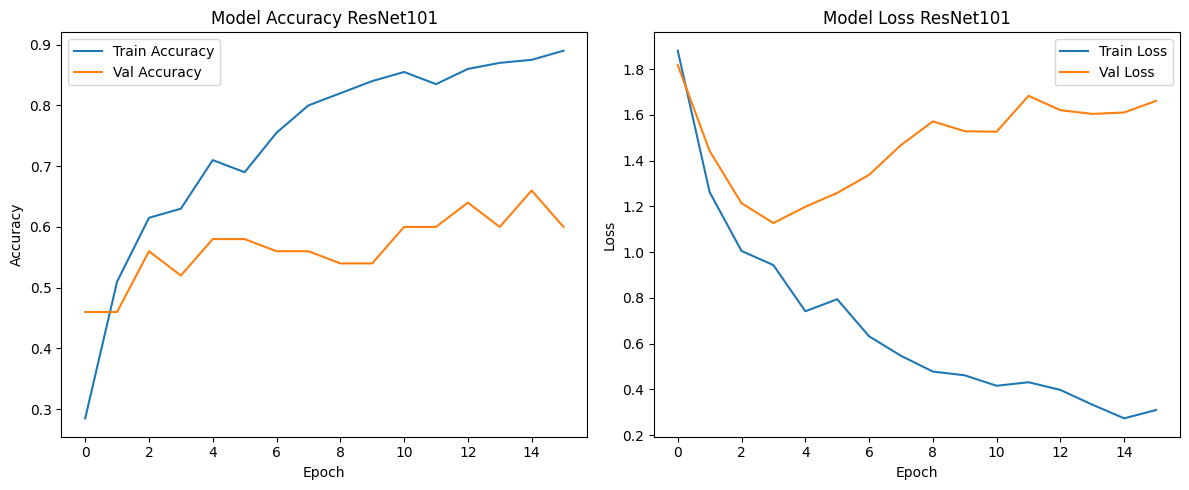

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_efficientnetb0.history['accuracy'], label='Train Accuracy')
plt.plot(history_efficientnetb0.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy EfficientNetB0')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_efficientnetb0.history['loss'],     label='Train Loss')
plt.plot(history_efficientnetb0.history['val_loss'], label='Val Loss')
plt.title('Model Loss EfficientNetB0')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.2 Visualize Training EfficientNetB1

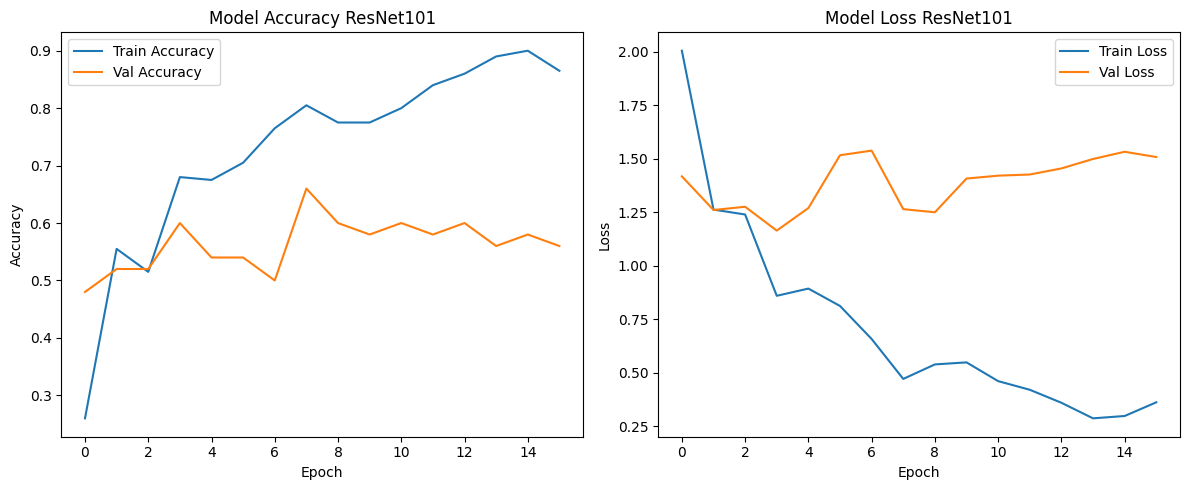

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_efficientnetb1.history['accuracy'], label='Train Accuracy')
plt.plot(history_efficientnetb1.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy EfficientNetB1')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_efficientnetb1.history['loss'],     label='Train Loss')
plt.plot(history_efficientnetb1.history['val_loss'], label='Val Loss')
plt.title('Model Loss EfficientNetB1')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.3 Visualize Training EfficientNetB2

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_efficientnetb2.history['accuracy'], label='Train Accuracy')
plt.plot(history_efficientnetb2.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy EfficientNetB2')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_efficientnetb2.history['loss'],     label='Train Loss')
plt.plot(history_efficientnetb2.history['val_loss'], label='Val Loss')
plt.title('Model Loss EfficientNetB2')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.3 Visualize Training EfficientNetB3

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_efficientnetb3.history['accuracy'], label='Train Accuracy')
plt.plot(history_efficientnetb3.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy EfficientNetB3')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_efficientnetb3.history['loss'],     label='Train Loss')
plt.plot(history_efficientnetb3.history['val_loss'], label='Val Loss')
plt.title('Model Loss EfficientNetB3')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

### 6.3 Visualize Training EfficientNetB4

In [ ]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history_efficientnetb4.history['accuracy'], label='Train Accuracy')
plt.plot(history_efficientnetb4.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy EfficientNetB4')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_efficientnetb4.history['loss'],     label='Train Loss')
plt.plot(history_efficientnetb4.history['val_loss'], label='Val Loss')
plt.title('Model Loss EfficientNetB4')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()

plt.tight_layout()
plt.show()

## 7.Evualte on test set

In [ ]:
test_loss_efficientb0, test_acc_effcientb0 = model_efficientb0.evaluate(test_dataset, verbose=0)
print(f'Test Loss EfficientNetB0: {test_loss_efficientb0:.4f}')
print(f'Test Accuracy EfficientNetB0: {test_acc_effcientb0:.4f}') 

Test Loss ResNet101: 0.9891
Test Accuracy ResNet101: 0.6393


In [ ]:
test_loss_efficientb1, test_acc_effcientb1 = model_efficientb1.evaluate(test_dataset, verbose=0)
print(f'Test Loss EfficientNetB1: {test_loss_efficientb1:.4f}')
print(f'Test Accuracy EfficientNetB1: {test_acc_effcientb1:.4f}') 

Test Loss ResNet101: 0.9504
Test Accuracy ResNet101: 0.6557


In [ ]:
test_loss_efficientb2, test_acc_effcientb2 = model_efficientb2.evaluate(test_dataset, verbose=0)
print(f'Test Loss EfficientNetB2: {test_loss_efficientb2:.4f}')
print(f'Test Accuracy EfficientNetB2: {test_acc_effcientb2:.4f}') 

In [ ]:
test_loss_efficientb3, test_acc_effcientb3 = model_efficientb3.evaluate(test_dataset, verbose=0)
print(f'Test Loss EfficientNetB3: {test_loss_efficientb3:.4f}')
print(f'Test Accuracy EfficientNetB3: {test_acc_effcientb3:.4f}') 

In [ ]:
test_loss_efficientb4, test_acc_effcientb4 = model_efficientb4.evaluate(test_dataset, verbose=0)
print(f'Test Loss EfficientNetB4: {test_loss_efficientb4:.4f}')
print(f'Test Accuracy EfficientNetB4: {test_acc_effcientb4:.4f}') 